# Benchmark calculating Shapley values

## Setup

In [9]:
import sys
sys.path.append('../')
import numpy as np
import pandas as pd
from exp_utils import CounterPlotNice
from sklearn.ensemble import RandomForestClassifier

Load data

In [10]:
# Download wine dataset
! wget https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv

# Read wine dataset
wine = pd.read_csv('winequality-red.csv', sep=';')

X, y = wine.drop('quality', axis=1), wine['quality']

# Transform X to numpy
X  = X.to_numpy()
# Transform y to binary
y = np.where(y > 5, 1, 0)

--2026-02-06 23:45:13--  https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv
Loaded CA certificate '/etc/ssl/certs/ca-certificates.crt'
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘winequality-red.csv.23’

winequality-red.csv     [     <=>            ]  82.23K  87.7KB/s    in 0.9s    

2026-02-06 23:45:15 (87.7 KB/s) - ‘winequality-red.csv.23’ saved [84199]



Train a model

In [11]:
# Make RF model for noisy dataset
model = RandomForestClassifier(random_state=42)

In [12]:
model.fit(X, y)

RandomForestClassifier(random_state=42)

Generate counterfactual explanations

In [13]:
exp_nice = CounterPlotNice(
    predict_fn=model.predict_proba,
    X_train=X,
    y_train=y,
    cat_feat=[])

In [14]:
# Select case with negative countershapley value
counterplot = exp_nice.explain(
    np.array([X[533]])
)[0]

Set up profiler

In [15]:
import cProfile, pstats
from counterplots.utils.process import calc_shapley_values_between, create_adapted_model_and_class

def get_function_stats(stats, function_name):
    """Extract pstatsb for a specific function."""
    for func, (primitive_calls, total_calls, total_time, cumulative_time, callers) in stats.stats.items():
        if function_name in func[2]:  # func[2] is the function name
            return {
                'function': func,
                'total_calls': total_calls,
                'primitive_calls': primitive_calls,
                'total_time': total_time,
                'cumulative_time': cumulative_time
            }
    return None

def profile_calc_shapley(
    f, 
    model, 
    size=1, 
    n=None,
    multiproc_kwargs={'min_size': 1e8}  # don't parallellize for profiling
    ):
    cf = f.copy()
    for i in range(size): cf[i] *= 1.1
    profiler = cProfile.Profile()
    profiler.enable()

    adapted_model, adapted_class = create_adapted_model_and_class(f, model.predict_proba, [0, 1])
    calc_shapley_values_between(
        f, 
        cf,
        predict_fn=adapted_model,
        sample_kwargs = {'n': n} if n is not None else None,
        multiproc_kwargs=multiproc_kwargs
    )

    profiler.disable()
    return pstats.Stats(profiler)

## Benchmark calculating exact Shapley values

If you have already run this, you can skip to [analysis](#plot-benchmarking-results)

In [8]:
def write_perf_shapley(sizes, n=None):
    import time
    import pandas as pd

    records = []

    for size in sizes:
        nruns = 100 // size  # reasonable sample size
        stats_objects = []

        start = time.time()
        for _ in range(nruns):
            stats = profile_calc_shapley(
                counterplot.factual,
                model,
                size=size,
                n=n
            )
            stats_objects.append(stats)

        print(
            f"Finished benchmarking size {size} "
            f"after {time.time() - start:.4f} seconds ({nruns} runs)"
        )
        print("Extracting data")

        for run_id, stats in enumerate(stats_objects):
            fs = get_function_stats(stats, "predict_proba")
            records.append({
                "size": size,
                "run": run_id,
                "cumulative_time": fs["cumulative_time"],
                "total_time": fs["total_time"],
                "total_calls": fs["total_calls"],
            })

    df = pd.DataFrame.from_records(records)

    for size, g in df.groupby("size"):
        fname = f"benchmarks/size{size}"
        if n is not None: fname += f"_sample={n}"
        fname += ".txt"

        g.to_csv(
            fname,
            sep="\t",
            index=False,
        )

In [9]:
sizes_exact = range(1, 12)
write_perf_shapley(sizes_exact)

Finished benchmarking size 1 after 5.4725 seconds (100 runs)
Extracting data
Finished benchmarking size 2 after 2.0986 seconds (50 runs)
Extracting data
Finished benchmarking size 3 after 2.4615 seconds (33 runs)
Extracting data
Finished benchmarking size 4 after 3.3439 seconds (25 runs)
Extracting data
Finished benchmarking size 5 after 5.1757 seconds (20 runs)
Extracting data
Finished benchmarking size 6 after 8.6734 seconds (16 runs)
Extracting data
Finished benchmarking size 7 after 14.4147 seconds (14 runs)
Extracting data
Finished benchmarking size 8 after 25.1353 seconds (12 runs)
Extracting data
Finished benchmarking size 9 after 44.7271 seconds (11 runs)
Extracting data
Finished benchmarking size 10 after 81.8172 seconds (10 runs)
Extracting data
Finished benchmarking size 11 after 146.2654 seconds (9 runs)
Extracting data


## Benchmark calculating approximate Shapley values

In [10]:
SAMPLE_RATIOS = (.2, .3, .4, .5)
sizes_approx = range(3, 12)
for sr in SAMPLE_RATIOS:
    print("Benchmarking sample ratio {}".format(sr))
    write_perf_shapley(sizes_approx, n=sr)

Benchmarking sample ratio 0.2


Finished benchmarking size 3 after 2.8686 seconds (33 runs)
Extracting data
Finished benchmarking size 4 after 2.7841 seconds (25 runs)
Extracting data
Finished benchmarking size 5 after 4.3626 seconds (20 runs)
Extracting data
Finished benchmarking size 6 after 6.3917 seconds (16 runs)
Extracting data
Finished benchmarking size 7 after 11.4823 seconds (14 runs)
Extracting data
Finished benchmarking size 8 after 20.4179 seconds (12 runs)
Extracting data
Finished benchmarking size 9 after 38.7969 seconds (11 runs)
Extracting data
Finished benchmarking size 10 after 72.2885 seconds (10 runs)
Extracting data
Finished benchmarking size 11 after 132.1098 seconds (9 runs)
Extracting data
Benchmarking sample ratio 0.3
Finished benchmarking size 3 after 2.4241 seconds (33 runs)
Extracting data
Finished benchmarking size 4 after 3.0730 seconds (25 runs)
Extracting data
Finished benchmarking size 5 after 4.6780 seconds (20 runs)
Extracting data
Finished benchmarking size 6 after 7.4611 seconds (

## Plot benchmarking results

In [16]:
PINK1 = "#ff0055"
PINK1_TR = "#ff0055d2"
RED1 = "#c20000"
BLUE1 = "#008ae7"
BLUE_TR = "#008ae7d2"
DARK_GREY = "#545454" 
LIGHT_GREY = "#e0e0e0" 

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

sizes_exact = range(1,12)
sizes_approx = range(3,12)

dfs = []
for size in sizes_exact:
    # ncalls never changes, bit silly to have as a column, but oh well
    df = pd.read_csv(
        f"benchmarks/size{size}.txt", 
        sep="\t", 
        )
    dfs.append(df)  # convert to ms

times = pd.concat(dfs, axis=0)

In [18]:
times

,size,run,cumulative_time,total_time,total_calls
0,1,0,0.086572,0.000155,3
1,1,1,0.068225,0.000115,3
2,1,2,0.059478,0.000115,3
3,1,3,0.058265,0.000103,3
4,1,4,0.066550,0.000105,3
...,...,...,...,...,...
4,11,4,16.214979,0.029122,2049
5,11,5,15.761034,0.021897,2049
6,11,6,15.765997,0.021354,2049
7,11,7,15.690450,0.021967,2049


In [26]:
g_exact = times.groupby('size')['cumulative_time']
m_exact, min_exact, max_exact = g_exact.mean(), g_exact.min(), g_exact.max()

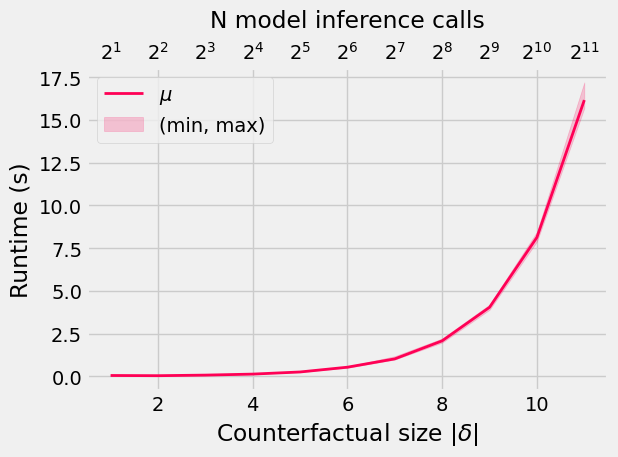

In [40]:
fig, ax1 = plt.subplots()
ax1.plot(sizes_exact, m_exact, c=PINK1, lw=2, label="$\mu$")
plt.fill_between(
    sizes_exact,
    min_exact, max_exact,
    alpha=.2,
    color=PINK1,
    label="(min, max)"
)

ax2 = ax1.secondary_xaxis('top')
ax2.set_xticks(
    sizes_exact, 
    [f"$2^{{{k}}}$" for k in sizes_exact]
)
ax2.set_xlabel('N model inference calls', labelpad=10)
ax1.set_xlabel("Counterfactual size $|\delta|$")
ax1.set_ylabel("Runtime (s)")

plt.legend()
plt.tight_layout()
plt.show()
fig.savefig("../_static/perf.png", dpi=300)

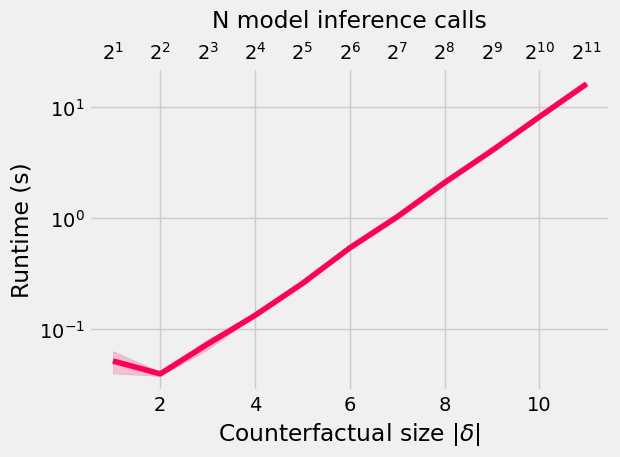

In [42]:
fig, ax1 = plt.subplots()
ax1.plot(sizes_exact, m_exact, c=PINK1)
plt.fill_between(
    sizes_exact,
    m_exact-s_exact, m_exact+s_exact,
    alpha=.2,
    color=PINK1
)

ax2 = ax1.secondary_xaxis('top')
ax2.set_xticks(
    sizes_exact, 
    [f"$2^{{{k}}}$" for k in sizes_exact]
)
ax2.set_xlabel('N model inference calls', labelpad=10)
ax1.set_xlabel("Counterfactual size $|\delta|$")
ax1.set_ylabel("Runtime (s)")

plt.tight_layout()
plt.yscale("log")
fig.savefig("../_static/perf_log.png", dpi=300)
plt.show()

Compare with subsampled Shapley values

In [44]:
import glob
import re
subsampled_files = glob.glob("benchmarks/*sample*.txt")
dfs = []
for f in subsampled_files:
    data = pd.read_csv(f, sep="\t")
    s = re.match(".*sample=(.*)\.txt", f).group(1)
    data['sample_ratio'] = s
    dfs.append(data)

df = pd.concat(dfs, ignore_index=True)


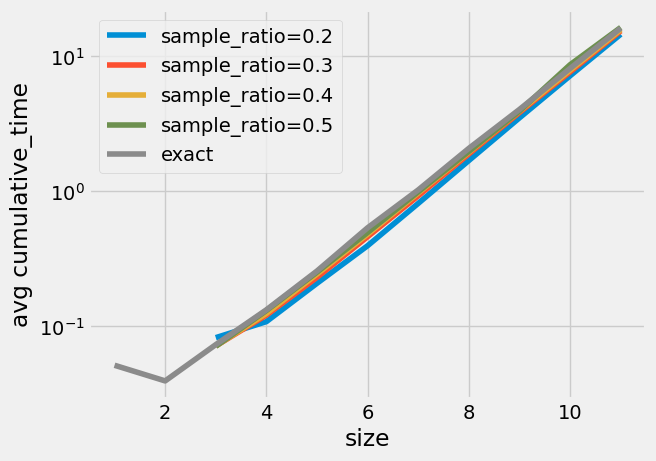

In [50]:
g_subs = df.groupby(['sample_ratio', 'size'], as_index=False)['cumulative_time']
m, s = g_subs.mean(), g_subs.std()

for ratio, g_sub in m.groupby('sample_ratio'):
    plt.plot(g_sub['size'], g_sub['cumulative_time'], label=f'sample_ratio={ratio}')
plt.plot(m_exact, label='exact')

plt.xlabel('size')
plt.ylabel('avg cumulative_time')
plt.legend()
plt.yscale('log')
plt.show()

Subsampled Shapley values still grow exponentially, of course. If we consistently sample 30% of an exponentially growing space, the sample will also grow exponentially. Just slower.

I expected to see a bigger difference here. Tragically, subsampling even a small percentage of possible subcoalition comparisons already requires a significant ratio of all subcoalitions.
A number that surprised me: when iterating only about 20% of all possible comparisons, you already need to know 80% of all subcoalitions.